# 02. json 메타데이터 EDA (약 이름·회사·외형)
- 목적: `01_eda.ipynb` 의 클래스 분포(`class_df`)에 json `images[]` 의 약 정보를 붙여서 봄
- 함수 위치: `src/eda.py`(eda_meta 부분), `src/visualize.py`(visualize_meta 부분)
- 이 노트북은 함수 결과 보고 해석만 함

### 6자리 숫자(K-코드) 처리 방법
- 이 숫자가 모든 표를 잇는 **키**임

| 어디에 있나 | 형태 | 예시 |
|---|---|---|
| 약 폴더명, `images[].drug_N`, `images[].dl_mapping_code` | 문자열 | `K-029451` |
| `annotations[].category_id`, `categories[].id`, `images[].dl_idx` | 정수 | `29451` |

- K-코드와 약 이름은 1:1. 같은 코드면 회사·모양·색·각인도 json 마다 전부 같음 (763개 확인)
- 그래서 **약 1개 = 1행** 표(`drug_df`)를 만들어 기존 `class_df`/`boxes_df` 의 `category_id` 에 merge 하면 끝
- 기존 6자리 분류는 그대로 두고, 이름·회사·외형은 옆에 컬럼으로 붙는 구조

### 표 3단계
- `pill_df`: json 1개 = 박스 1개 = 1행 (763행)
- `drug_df`: 약 1개 = 1행 (56행)
- `merged`: 기존 `class_df` + `drug_df` (56행)

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.utils import load_config
from src.visualize import set_korean_font

set_korean_font()                              # 그래프 한글 깨짐 방지
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)      # 약 이름 목록이 길어서 넓게

CONFIG = "configs/base.yaml"
cfg = load_config(CONFIG)
d = cfg["data"]
ANN_DIR = d["train_annotations"]   # 조합폴더/약폴더/*.json 구조
IMG_DIR = d["train_images"]        # 이미지 폴더. None 이면 이미지 존재 검사는 생략됨

ModuleNotFoundError: No module named 'imp'

## 1. annotation ↔ 이미지 연결 확인
- json 1개마다 아래를 검사하고, 항목별 실패 개수(`n_fail`)를 셈. **0 이면 정상**
  - json 구조: 이미지·박스·카테고리가 각 1개씩인지
  - 파일명: json 파일명 = `file_name`, `file_name` 이 조합폴더명으로 시작하는지
  - 코드: 약폴더 코드가 조합에 들어있는지, `dl_mapping_code`·`category_id` 와 같은지
  - json 내부: `categories.id/name` ↔ `category_id/dl_name`, `annotation.image_id` ↔ `images.id`
  - 박스: 이미지 밖으로 안 나가는지, 크기가 0 보다 큰지
  - 이미지: `IMG_DIR` 에 실제 파일이 있는지 (`IMG_DIR` 줄 때만)
- 반대 방향(이미지는 있는데 json 없음)은 01 노트북 `image_json_pairs` / `missing_jsons` 로 봄 → 8개 누락 확인됨

In [2]:
from src.eda import annotation_consistency

link = annotation_consistency(ANN_DIR, IMG_DIR)
link   # n_fail > 0 인 행은 detail 에 문제 json 경로 예시가 나옴

,check,n_checked,n_fail,detail
0,images 1개,763,0,
1,annotations 1개,763,0,
2,categories 1개,763,0,
3,json 파일명 == file_name,763,0,
4,file_name이 조합폴더로 시작,763,0,
5,약폴더 코드가 조합에 포함,763,0,
6,약폴더 == dl_mapping_code,763,0,
7,category_id == 코드 숫자,763,0,
8,categories.id == category_id,763,0,
9,categories.name == dl_name,763,0,


**인사이트(초안):**
- 폴더·파일명·`category_id`·`image_id`·약 이름 연결은 json 763개 전부 일치
- `bbox 이미지 안` 실패 1건 = 01 노트북 `find_label_issues` 의 out_of_bounds(K-018357)와 같은 박스 → 정제(데이터 B) 대상
- (이 실행본은 이미지 폴더 없이 돌린 것. 이미지 폴더 있는 환경에서 다시 돌리면 `이미지 파일 존재` 행이 추가됨)

## 2. 약 메타 표 만들기
- 순서: 박스 단위(`pill_df`) → 약 단위(`drug_df`) → 기존 `class_df` 와 합치기(`merged`)
- `merge_class_meta` 는 `validate="1:1"` 로 합쳐서 키가 중복되면 바로 에러남 → 키 검사 겸용
- `has_meta`: 메타가 붙었는지 / `name_match`: 기존 클래스 이름과 json 약 이름이 같은지

In [3]:
from src.dataset import build_class_map, load_records
from src.eda import class_distribution, drug_table, load_pill_meta, merge_class_meta, records_to_frames

# 01 노트북과 같은 방식으로 기존 표 만들기
records, categories = load_records(ANN_DIR)
class_map = build_class_map(records, categories)
images_df, boxes_df = records_to_frames(records, class_map)
class_df = class_distribution(boxes_df)

# json 메타 표
pill_df = load_pill_meta(ANN_DIR)   # json 1개 = 박스 1개 = 1행
drug_df = drug_table(pill_df)       # 약(K-코드) 1개 = 1행
merged = merge_class_meta(class_df, drug_df)

print("pill_df", pill_df.shape, "/ drug_df", drug_df.shape, "/ merged", merged.shape)
print("메타 붙은 클래스:", merged["has_meta"].sum(), "/ 이름 일치:", merged["name_match"].sum())
merged.head(10)

pill_df (763, 40) / drug_df (56, 22) / merged (56, 17)
메타 붙은 클래스: 56 / 이름 일치: 56


,category_id,name,n_boxes,n_images,share_%,code,dl_name,dl_company,dosage,look,print_side,di_etc_otc_code,class_name,leng_long,n_back,name_match,has_meta
0,3351,일양하이트린정 2mg,153,153,20.05,K-003351,일양하이트린정 2mg,일양약품(주),정제,주황·원형,양면,전문의약품,기타의 비뇨생식기관 및 항문용약,7.01,4,True,True
1,3483,기넥신에프정(은행엽엑스)(수출용),45,45,5.90,K-003483,기넥신에프정(은행엽엑스)(수출용),에스케이케미칼(주),정제,초록·장방형,양면,일반의약품,기타의 순환계용약,11.10,0,True,True
2,35206,아토젯정 10/40mg,37,37,4.85,K-035206,아토젯정 10/40mg,한국엠에스디(주),정제,하양·타원형,한 면,전문의약품,동맥경화용제,17.00,0,True,True
3,16262,크레스토정 20mg,23,23,3.01,K-016262,크레스토정 20mg,한국아스트라제네카(주),정제,분홍·원형,한 면,전문의약품,동맥경화용제,9.20,0,True,True
4,21325,아토르바정 10mg,22,22,2.88,K-021325,아토르바정 10mg,(주)유한양행,정제,하양·타원형,양면,전문의약품,동맥경화용제,9.70,0,True,True
5,16232,리피토정 20mg,21,21,2.75,K-016232,리피토정 20mg,한국화이자제약(주),정제,하양·원형,양면,전문의약품,동맥경화용제,7.50,0,True,True
6,3832,뉴로메드정(옥시라세탐),20,20,2.62,K-003832,뉴로메드정(옥시라세탐),고려제약(주),정제,하양·장방형,양면,전문의약품,기타의 중추신경용약,17.70,0,True,True
7,20238,플라빅스정 75mg,20,20,2.62,K-020238,플라빅스정 75mg,(주)한독,정제,분홍·원형,양면,전문의약품,동맥경화용제,8.50,0,True,True
8,36637,로수젯정10/5밀리그램,19,19,2.49,K-036637,로수젯정10/5밀리그램,한미약품(주),정제,노랑·타원형,양면,전문의약품,동맥경화용제,11.00,2,True,True
9,16548,가바토파정 100mg,18,18,2.36,K-016548,가바토파정 100mg,동아에스티(주),정제,미상·미상,미상,전문의약품,항전간제,0.00,0,True,True


- 박스 단위 분석(박스 크기 x 모양 등)이 필요하면 `boxes_df` 에 바로 붙이면 됨. 약 1개에 박스 여러 개라 `validate="m:1"`

In [4]:
boxes_meta = boxes_df.merge(
    drug_df.drop(columns=["n_boxes", "n_images"]),   # boxes_df 와 겹치는 집계 컬럼은 뺌
    on="category_id", how="left", validate="m:1",
)
print(len(boxes_df), "→", len(boxes_meta))   # 행 수가 같아야 정상
boxes_meta[["file_name", "category_id", "code", "dl_name", "dl_company", "look", "box_w", "box_h"]].head()

763 → 763


,file_name,category_id,code,dl_name,dl_company,look,box_w,box_h
0,K-001900-016548-019607-029451_0_2_0_2_70_000_200.png,1900,K-001900,보령부스파정 5mg,보령제약(주),하양·장방형,189,190
1,K-001900-016548-019607-029451_0_2_0_2_70_000_200.png,16548,K-016548,가바토파정 100mg,동아에스티(주),미상·미상,239,239
2,K-001900-016548-019607-029451_0_2_0_2_70_000_200.png,19607,K-019607,스토가정 10mg,보령제약(주),하양·원형,155,150
3,K-001900-016548-019607-029451_0_2_0_2_70_000_200.png,29451,K-029451,레일라정,(주)한국피엠지제약,노랑·타원형,392,264
4,K-001900-016548-019607-029451_0_2_0_2_75_000_200.png,1900,K-001900,보령부스파정 5mg,보령제약(주),하양·장방형,181,181


## 3. 결측치
- 결측을 3종류로 나눠서 셈
  - `n_nan`: json 에 필드 자체가 없음 → 진짜 결측
  - `n_zero`: 크기(mm)가 0 → 결측으로 봄
  - `n_empty`: 빈 문자열 `""` → 필드에 따라 뜻이 다름
- `empty_means` 가 `결측` 이 아니면 빈 값 = '해당 없음' (단색, 각인 없음, 분할선 없음) → 문제 아님
- `missing_%` 는 이 기준으로 계산한 진짜 결측 비율

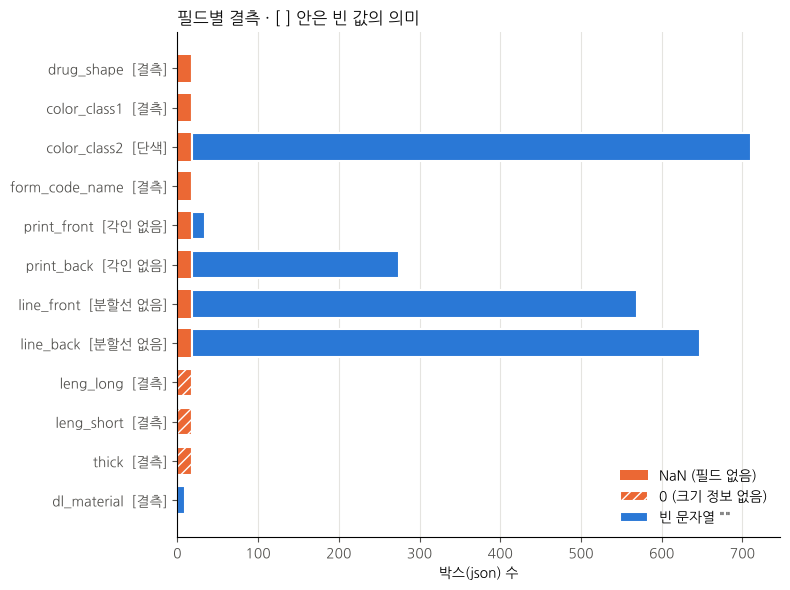

,group,field,n_nan,n_zero,n_empty,missing_%,empty_means,n_unique,drugs_missing
0,식별,dl_mapping_code,0,0,0,0.0,결측,56,
1,식별,dl_name,0,0,0,0.0,결측,56,
2,식별,dl_company,0,0,0,0.0,결측,30,
3,외형,drug_shape,18,0,0,2.4,결측,5,가바토파정 100mg
4,외형,color_class1,18,0,0,2.4,결측,9,가바토파정 100mg
5,외형,color_class2,18,0,693,2.4,단색,4,가바토파정 100mg
6,외형,form_code_name,18,0,0,2.4,결측,7,가바토파정 100mg
7,외형,dl_custom_shape,0,0,0,0.0,결측,5,
8,외형,print_front,18,0,16,2.4,각인 없음,49,가바토파정 100mg
9,외형,print_back,18,0,256,2.4,각인 없음,24,가바토파정 100mg


In [5]:
from src.eda import missing_value_report
from src.visualize import plot_missing

miss = missing_value_report(pill_df)
plot_missing(miss)
miss

**인사이트(초안):**
- 진짜 결측은 **가바토파정 100mg(K-016548) 한 약**에 몰려 있음
  - 모양·색·제형·각인 필드가 아예 없음, 크기(leng_long/short/thick)는 0.0
  - 박스 18개(2.4%) 해당 → 이미지 보고 손으로 채우거나 '미상'으로 둠
- `dl_material` 빈 값 9개 = 다보타민큐정·트루비타정(비타민 복합제). 모델엔 안 쓰는 필드라 무시해도 됨
- `back_color`, `light_color` 는 값이 1종류뿐 → 분석 의미 없음 (테스트 이미지 배경이 다르면 주의)

## 4. 이름 · 회사
- 기존 클래스 분포 그래프에 이름·회사·K-코드를 같이 붙여서 봄
- 회사별은 박스 수 기준 상위 15개

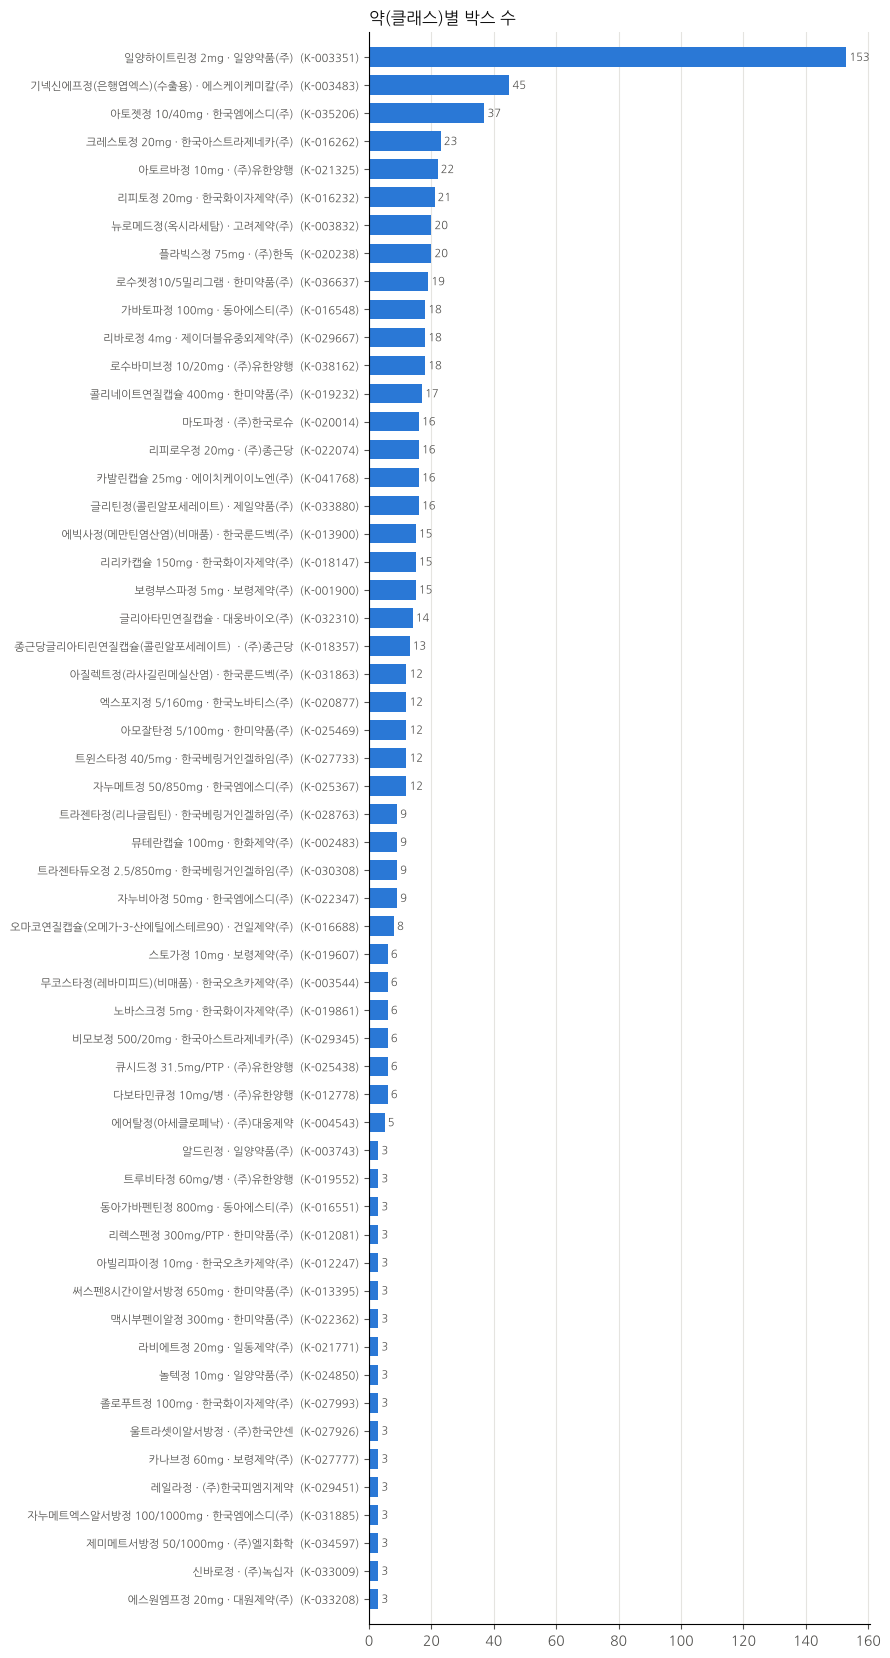

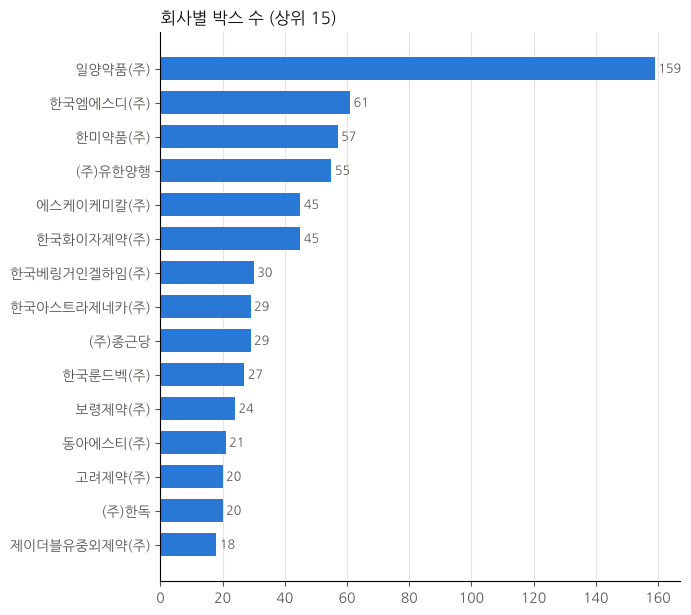

In [6]:
from src.eda import meta_counts
from src.visualize import plot_drug_bars, plot_meta_bar

plot_drug_bars(merged)   # 약 56종 전체. 라벨 = 이름 · 회사 (K-코드)
plot_meta_bar(meta_counts(pill_df, "dl_company"), "dl_company", top=15, title="회사별 박스 수 (상위 15)")

**인사이트(초안):**
- 일양하이트린정 2mg(K-003351) 한 약이 박스 153개로 전체의 20%. 나머지는 3~45개 → 심한 불균형
- 회사도 일양약품(주)가 159개로 1위인데, 대부분 이 약 하나 때문

## 5. 외형 클래스 (모델이 실제로 보는 정보)
- 그래프 값은 `n_drugs`(약 종류 수). 박스 수로 보고 싶으면 `value="n_boxes"`
- `dosage`: 정제/캡슐, `form_code_name`: 세부 제형, `print_side`: 각인 있는 면 수

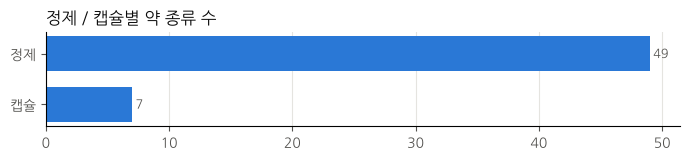

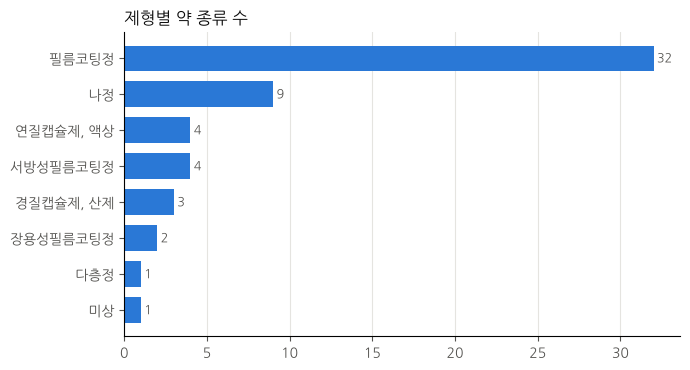

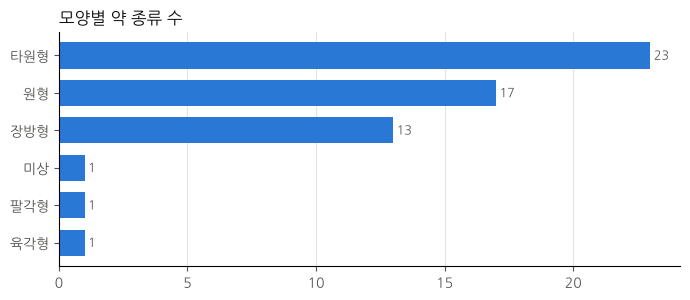

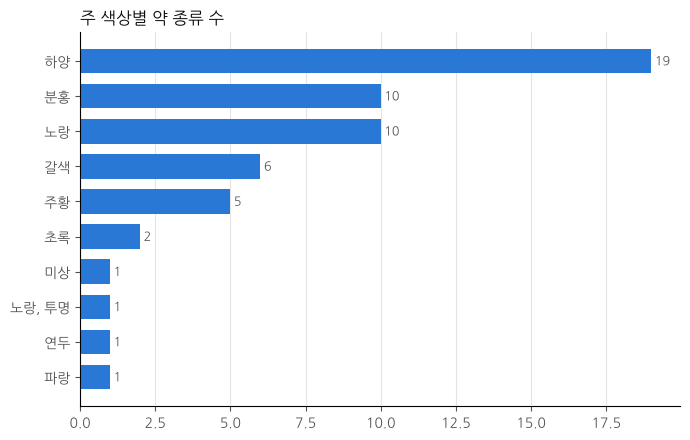

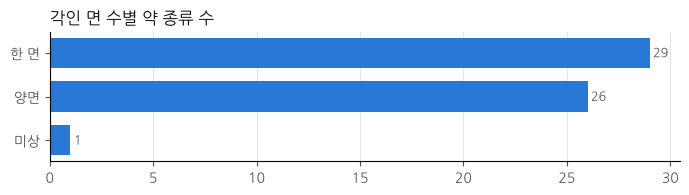

In [7]:
for col, title in [
    ("dosage", "정제 / 캡슐"),
    ("form_code_name", "제형"),
    ("drug_shape", "모양"),
    ("color_class1", "주 색상"),
    ("print_side", "각인 면 수"),
]:
    plot_meta_bar(meta_counts(pill_df, col), col, value="n_drugs", title=f"{title}별 약 종류 수")

### 닮은꼴 그룹 (`look` = 색·모양)
- 새로 만든 파생 클래스. 예: `하양·원형`
- 한 그룹에 약이 여러 개면 색·모양으로는 구분 불가 → 각인·크기로만 구분해야 하는 **헷갈리는 클래스**
- 히트맵 칸 숫자 = 그 색·모양 조합의 약 종류 수

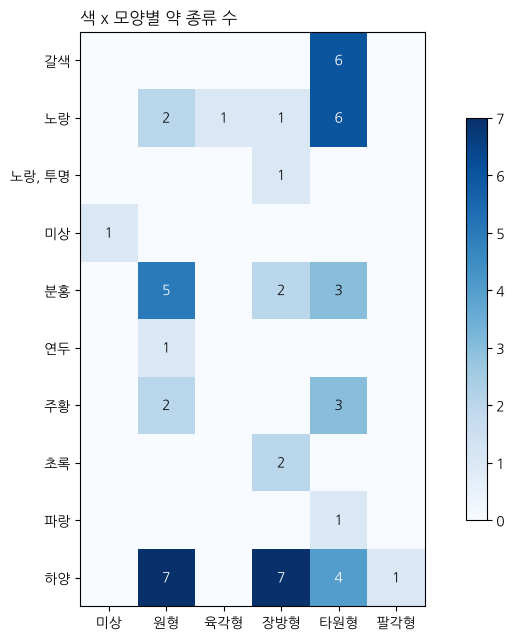

,look,n_drugs,n_boxes,drugs
0,하양·원형,7,69,"리피토정 20mg, 리피로우정 20mg, 아질렉트정(라사길린메실산염), 스토가정 10mg, 무코스타정..."
1,하양·장방형,7,62,"뉴로메드정(옥시라세탐), 리리카캡슐 150mg, 보령부스파정 5mg, 리렉스펜정 300mg/PTP, ..."
2,노랑·타원형,6,58,"로수젯정10/5밀리그램, 에빅사정(메만틴염산염)(비매품), 엑스포지정 5/160mg, 비모보정 500..."
3,갈색·타원형,6,56,"콜리네이트연질캡슐 400mg, 글리아타민연질캡슐, 종근당글리아티린연질캡슐(콜린알포세레이트) , 다보타..."
4,분홍·원형,5,71,"크레스토정 20mg, 플라빅스정 75mg, 마도파정, 트라젠타정(리나글립틴), 에스원엠프정 20mg"
5,하양·타원형,4,74,"아토젯정 10/40mg, 아토르바정 10mg, 트윈스타정 40/5mg, 동아가바펜틴정 800mg"
6,분홍·타원형,3,42,"로수바미브정 10/20mg, 아모잘탄정 5/100mg, 자누메트정 50/850mg"
7,주황·타원형,3,28,"글리틴정(콜린알포세레이트), 트라젠타듀오정 2.5/850mg, 놀텍정 10mg"
8,주황·원형,2,162,"일양하이트린정 2mg, 자누비아정 50mg"
9,초록·장방형,2,54,"기넥신에프정(은행엽엑스)(수출용), 뮤테란캡슐 100mg"


In [8]:
from src.eda import look_alike_groups
from src.visualize import plot_look_heatmap

plot_look_heatmap(drug_df)
look_alike_groups(drug_df)   # 2종 이상 모인 그룹만

**인사이트(초안):**
- 하양·원형, 하양·장방형이 각 7종, 노랑·타원형, 갈색·타원형(연질캡슐)이 각 6종
- 이 그룹끼리 혼동 행렬에서 헷갈리는지 꼭 확인
- 각인으로 구분해야 하니 입력 해상도 키우기(D6) 근거로 씀

## 6. 의약 정보 (설명용)
- 사진으론 안 보이는 정보라 모델 성능과는 직접 관련 없음. 보고서 설명용

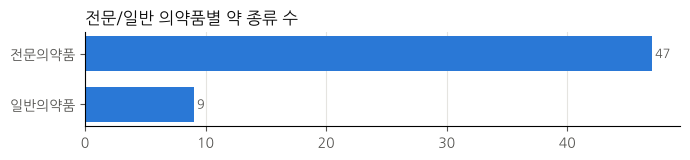

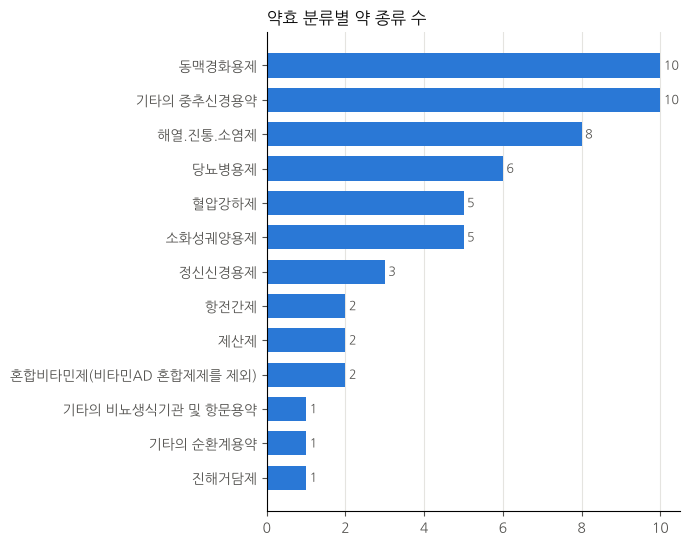

In [9]:
plot_meta_bar(meta_counts(pill_df, "di_etc_otc_code"), "di_etc_otc_code", value="n_drugs",
              title="전문/일반 의약품별 약 종류 수")
plot_meta_bar(meta_counts(pill_df, "class_name"), "class_name", value="n_drugs",
              title="약효 분류별 약 종류 수")

## 7. 촬영 조건
- 파일명 `..._0_2_{면}_2_{각도}_000_200` 구조
  - 3번째 숫자: 0=앞면, 1=뒷면
  - 5번째 숫자: 카메라 각도(`camera_la`) 70/75/90
- 아래 코드로 파일명 값과 json 값이 같은지 확인. 둘 다 `True` 면 파일명만 보고도 촬영 조건 알 수 있음
- 교차표는 이미지 수 기준 (박스 수 아님)

In [10]:
from src.eda import shooting_conditions

print("면 일치:", (pill_df["fn_side"] == pill_df["drug_dir"]).all(),
      "/ 각도 일치:", (pill_df["fn_camera_la"] == pill_df["camera_la"]).all())
shooting_conditions(pill_df)

면 일치: True / 각도 일치: True


drug_dir,뒷면,앞면,합계
camera_la,,,
70,1,71,72
75,1,74,75
90,2,83,85
합계,4,228,232


**인사이트(초안):**
- 뒷면 사진은 232장 중 4장뿐. 테스트에 뒷면이 많으면 성능이 떨어질 수 있음
- 카메라 각도 70/75/90 은 고르게 분포

## 8. 실제 크기 vs 박스 크기
- 같은 각도에서 찍으면 거리가 같으니 mm당 픽셀 수(`px_per_mm`)가 비슷해야 정상
- 산점도에서 직선을 크게 벗어난 점 = bbox 나 크기 정보 오류 후보
- `size_consistency` 는 각도별 중앙값보다 25% 넘게 벗어난 박스를 `suspect=True` 로 표시
- 알약이 비스듬히 놓이면 박스가 조금 작게 잡히는 건 정상 → 오류 확정 아님, 확인 후보

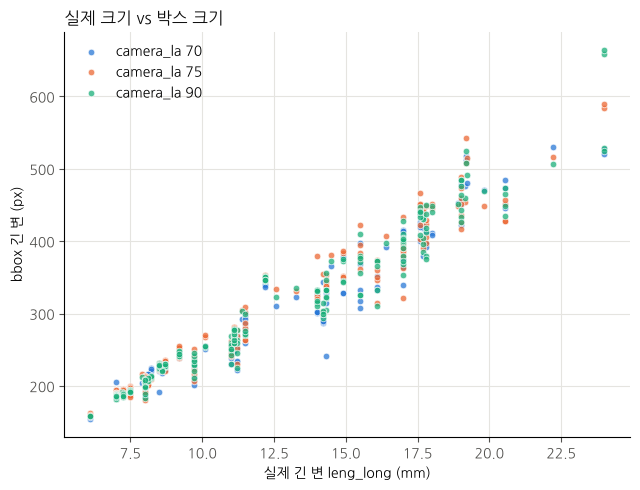

의심: 2 / 745


,file_name,code,dl_name,camera_la,leng_long,box_w,box_h,px_per_mm,ratio_to_median,suspect
0,K-003351-019232-029667_0_2_1_2_70_000_200.png,K-019232,콜리네이트연질캡슐 400mg,70,14.3,232,241,16.853147,0.678,True
1,K-003483-025367-027733-035206_0_2_0_2_75_000_200.png,K-035206,아토젯정 10/40mg,75,17.0,321,283,18.882353,0.742,True


In [11]:
from src.eda import size_consistency
from src.visualize import plot_size_scatter

plot_size_scatter(pill_df)
size = size_consistency(pill_df)
print("의심:", size["suspect"].sum(), "/", len(size))
size[size["suspect"]]

## 정리
- 연결:
- 결측:
- 헷갈리는 클래스(look 그룹):
- 정제(데이터 B)에 넘길 항목: